# 02 · Geometry mode: angles as qubit circles

**Goal:** see why angle-valued data fit a qubit naturally, and check that the gain comes from geometry, not from quantum effects.

What you need:
- `pip install .` (Python 3.12). Everything runs offline, on exact simulation.
- About a minute of compute.

Previous: [01 · Quickstart](01-quickstart.ipynb) · Next: [03 · Reproduce](03-reproduce.ipynb)

## 1. The data: protein backbone angles

Each row is one amino-acid residue from the Protein Data Bank (CC0).
The columns are the backbone dihedral angles φ and ψ of the residue and its two neighbours on each side, in degrees.
The label says whether the residue sits in a β-strand.

In [1]:
from qlassifier import load_dataset

data = load_dataset("protein_angles")
print(data.info.name, "·", data.X.shape[0], "residues ·", data.groups.nunique(), "protein chains")
print("strand share:", round(data.y.mean(), 3))
data.X.head()

Protein backbone angles · 4000 residues · 1773 protein chains
strand share: 0.249


,phi_m2,psi_m2,phi_m1,psi_m1,phi_0,psi_0,phi_p1,psi_p1,phi_p2,psi_p2
0,-99.868771,139.767556,-129.335405,155.870697,-79.330727,168.455906,-60.525092,-38.323772,-66.544445,-39.227886
1,-103.589327,137.973919,-118.912317,122.859089,-129.663885,138.814321,-99.141023,167.733816,-67.837392,-13.020544
2,-62.525792,-37.718244,-70.175679,-28.954103,-75.832796,-27.346007,-80.196848,-38.333100,-129.195194,71.575427
3,-62.605389,-47.972470,-65.018384,-38.903259,-61.811617,-39.369419,-60.645719,-47.394944,-59.754168,-46.795620
4,-66.608562,-42.428984,-59.230389,-41.157993,-63.417123,-42.009451,-62.213106,-45.687823,-61.385439,-36.645642


## 2. The seam problem

Angles wrap around: −179° and +179° are only 2° apart.
A model that sees raw numbers thinks they are 358° apart.
Strands live right on that seam: their ψ angle sits near ±180°.

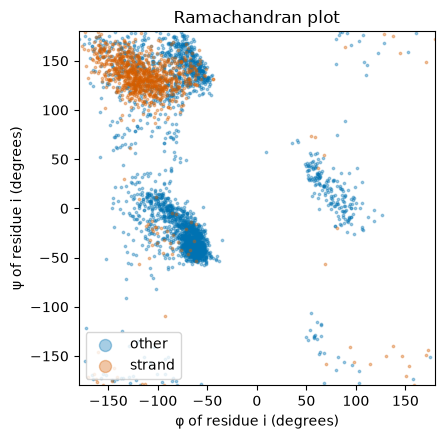

strand residues with |ψ| > 150°: 20%


In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4.6, 4.6))
for label, color, name in [(0, "#0072B2", "other"), (1, "#D55E00", "strand")]:
    rows = data.y == label
    ax.scatter(data.X.loc[rows, "phi_0"], data.X.loc[rows, "psi_0"], s=3, alpha=0.35, color=color, label=name)
ax.set(xlabel="φ of residue i (degrees)", ylabel="ψ of residue i (degrees)", xlim=(-180, 180), ylim=(-180, 180))
ax.set_title("Ramachandran plot")
ax.legend(markerscale=5, loc="lower left")
plt.show()

strands = data.X.loc[data.y == 1, "psi_0"]
print(f"strand residues with |ψ| > 150°: {(strands.abs() > 150).mean():.0%}")

## 3. One qubit per angle

Geometry mode rotates one qubit per angle: RY(2πx/P) on |0⟩, with period P = 360°.
The qubit's Bloch vector then walks around a circle, so the seam disappears.
Here is the check with Qiskit's own statevector simulator:

In [3]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Pauli, Statevector


def bloch_vector(degrees):
    qc = QuantumCircuit(1)
    qc.ry(np.deg2rad(degrees), 0)
    state = Statevector(qc)
    return np.array([state.expectation_value(Pauli(p)).real for p in "XYZ"])


for a, b in [(179, -179), (10, 30)]:
    gap = np.linalg.norm(bloch_vector(a) - bloch_vector(b))
    print(f"{a:>4}° vs {b:>4}°: raw difference {abs(a - b):>3}°, Bloch-vector distance {gap:.3f}")

 179° vs -179°: raw difference 358°, Bloch-vector distance 0.035
  10° vs   30°: raw difference  20°, Bloch-vector distance 0.347


The kernel on such a qubit is exp(−2γ(1 − cos Δθ)), the von Mises kernel of directional statistics.
It is smooth across the seam.

## 4. Why not two angles on one qubit?

The default encoding packs two ordinary features per qubit (RX then RY).
For angles that fails: the pair (a, b) and the pair (π − a, b + π) land on the same Bloch vector.
A torus (two angles) does not fit on a sphere (one qubit).

In [4]:
from qlassifier.encoding import bloch_from_angles

a, b = 0.4, 1.1
print(bloch_from_angles(np.array([a, b, 0.0])).round(6))
print(bloch_from_angles(np.array([np.pi - a, b + np.pi, 0.0])).round(6))

[ 0.820856 -0.389418  0.41779 ]
[ 0.820856 -0.389418  0.41779 ]


So geometry mode spends one qubit per angle: 10 angles → 10 qubits, still with no two-qubit gates.

## 5. Geometry mode against the generic encoding

One chain-grouped split: no protein chain appears in both training and test data.

In [5]:
from sklearn.metrics import balanced_accuracy_score

from qlassifier import Qlassifier

X_train, X_test, y_train, y_test = data.split(seed=0)
geometry = Qlassifier(geometry=data.geometry, random_state=0).fit(X_train, y_train)
generic = Qlassifier(random_state=0).fit(X_train, y_train)
for name, model in [("geometry mode", geometry), ("generic encoding", generic)]:
    ba = balanced_accuracy_score(y_test, model.predict(X_test))
    print(f"{name:<17} balanced accuracy {ba:.3f} · {model.n_qubits_} qubits")

geometry mode     balanced accuracy 0.901 · 10 qubits
generic encoding  balanced accuracy 0.880 · 5 qubits


## 6. The classical twin

The same geometry can be built by hand: sin and cos of each angle, then an ordinary RBF kernel.
That classical twin gives exactly the same kernel matrix as geometry mode:

In [6]:
from qlassifier.encoding import Encoding, twin_features
from qlassifier.tuning import gamma0, gaussian_gram

X = X_train.to_numpy()[:500]
encoding = Encoding.plan(X.shape[1], data.geometry, list(X_train.columns)).fit(X)
bloch = encoding.bloch(X)  # one Bloch vector per angle: shape (rows, 10, 3)
twin = twin_features(X, encoding)  # sin and cos per angle: shape (rows, 20)
K_quantum = gaussian_gram(bloch, bloch, gamma0(bloch))
K_twin = gaussian_gram(twin, twin, gamma0(twin))
print(f"largest difference between the two kernel matrices: {np.abs(K_quantum - K_twin).max():.1e}")

largest difference between the two kernel matrices: 5.6e-16


**What this means.**
- The gain of geometry mode is the gain of a good geometric prior.
- The qubit delivers that prior natively, with one rotation per angle.
- A classical model gets it too, once someone engineers the sin/cos features.
- So we always report the twin next to geometry mode, and we never claim a quantum advantage.

## 7. The shipped ten-seed result

The benchmark compares geometry mode with every baseline on ten chain-grouped splits, the twin included.

In [7]:
from qlassifier import BenchmarkResult

result = BenchmarkResult.cached("protein_angles")
result.plot("leaderboard");

In [8]:
print(result.summary())

Protein backbone angles · 13 models × 10 seeds · native · BA (corrected 95% CI) · complete
model                        mean ± sd           95% CI       Qlassifier − model  Qlassifier wins
Qlassifier *             0.898 ± 0.009   [0.883, 0.913]                        —                —
Classical twin *         0.898 ± 0.009   [0.883, 0.913]     +0.0 pp [+0.0, +0.0]             0/10
Separable *              0.888 ± 0.008   [0.875, 0.901]     +1.0 pp [-0.2, +2.2]             9/10
Gradient boosting *      0.888 ± 0.005   [0.880, 0.896]     +1.0 pp [-0.2, +2.2]            10/10
MLP *                    0.884 ± 0.008   [0.871, 0.898]     +1.3 pp [-0.3, +3.0]             9/10
Random forest            0.883 ± 0.007   [0.872, 0.894]     +1.5 pp [+0.0, +2.9]            10/10
FQK-bw full              0.878 ± 0.013   [0.857, 0.900]     +2.0 pp [+0.0, +3.9]            10/10
PQK                      0.878 ± 0.009   [0.863, 0.893]     +2.0 pp [+0.7, +3.3]            10/10
FQK-bw linear            0.

**Result.**
- The table lists every model's balanced accuracy with its corrected 95% confidence interval; `*` marks models statistically tied with the best.
- The classical twin matches geometry mode, as section 6 predicts.
- Against the best tuned classical model the difference is small: the paper reports it with its confidence interval and every earlier run (section "Geometry mode on protein angles").

Next: [03 · Reproduce](03-reproduce.ipynb) reruns part of the benchmark and summarises noise and cost.